In [1]:
#utils
import pandas as pd
import numpy as np
import contextlib
import os
import warnings

#visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

#machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, auc
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve


warnings.filterwarnings("ignore")

#it's important that eager execution is enabled
#it comes as a default setting in tensorflow 2.0
if tf.executing_eagerly():
    print("Eager execution is enabled.")
else:
    print("Eager execution is not enabled.")


Eager execution is enabled.


In [2]:
df = pd.read_csv('SimData.csv')
df = df.head(500)

In [3]:
#this gives us the duimension of the dataset we're working with.
df.shape

(500, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   isghost  500 non-null    int64  
 1   chi2     500 non-null    float64
 2   nb_hits  500 non-null    int64  
 3   qop      500 non-null    float64
 4   tx       500 non-null    float64
 5   ty       500 non-null    float64
 6   x        500 non-null    float64
 7   y        500 non-null    float64
 8   z        500 non-null    float64
dtypes: float64(7), int64(2)
memory usage: 35.3 KB


In [5]:
df.isghost.describe()

count    500.0000
mean       0.1000
std        0.3003
min        0.0000
25%        0.0000
50%        0.0000
75%        0.0000
max        1.0000
Name: isghost, dtype: float64

# Visualize all the data points where ghost=1 and any feature has an outlier value

qop stands for "charge-to-over-momentum" ratio, is a measure of the electric charge of a particle relative to its momentum

In [6]:
target_feature = "isghost"
columns = df.drop(columns=target_feature).columns
#instantiate two more datasets one to contain the normal data
#and the other to hold the anomalous instances
train_normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

In [7]:
#also instantiate a dataframe to carry all the features
#and a second one to instead contain the target variable
def get_normal_data(df):
    df = df.sample(frac=1)
    features = df.drop([target_feature], axis=1)
    label = df[target_feature]

    #the stratify parameter here is set to be "isghost" meaning that the 
    #proportions of ghost and normal tracks in both train and test datasets
    #will be kept the same...
    x_train, x_test, y_train, y_test = train_test_split(
        features, label, test_size=0.2, stratify=label
    )

    #remember that at least for the autoencoders we're gonna use just the 
    #normal instances during the training phase so we have to filter those in x_train
    train_index = y_train[y_train == 0].index
    train_normal_data = x_train.loc[train_index]

    return train_normal_data, x_train, y_train, x_test, y_test

In [8]:
train_normal_data, x_train, y_train, x_test, y_test = get_normal_data(df)

This is to show the distribution of the features before standardization.

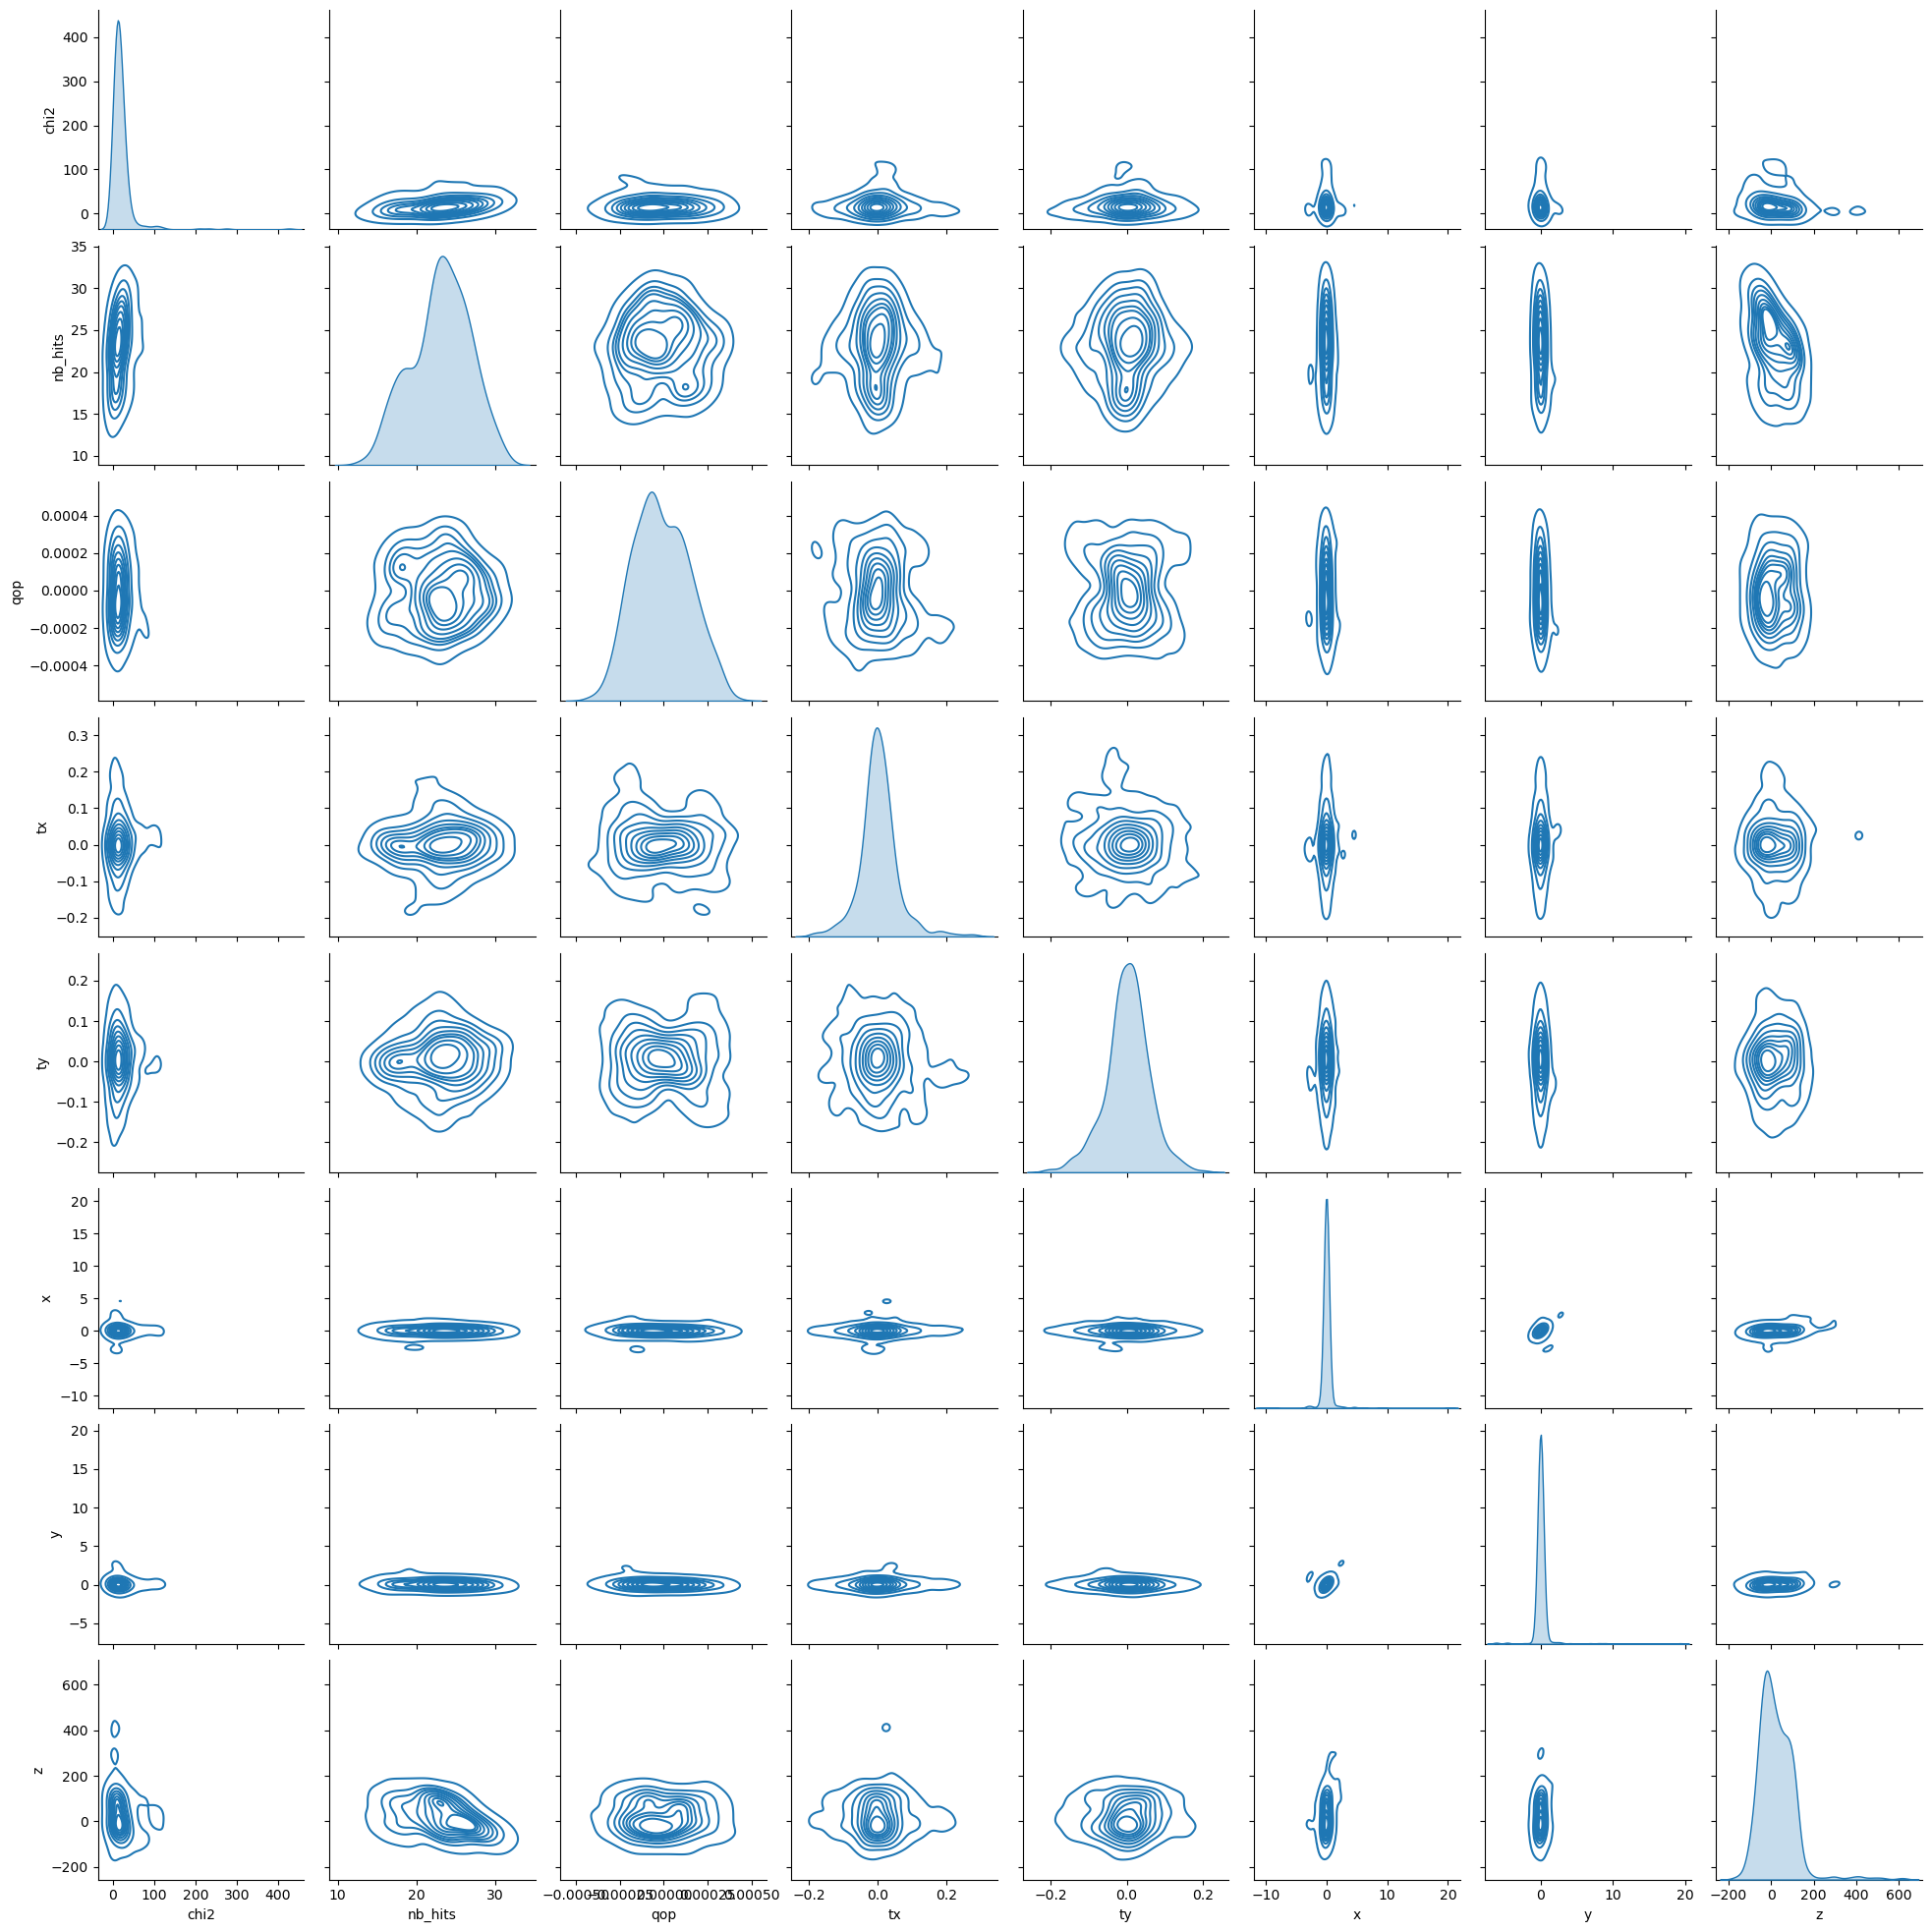

In [9]:
sns.pairplot(x_train, kind='kde')


In [10]:
def standardize_normalize(train_x, normal_train_data, test_data):
    #here I need to rescale the data as the featurea have different ranges 


    #Don't forget that testing data points represent real-world data.
    #Feature normalization (or data standardization) of the explanatory (or predictor) variables
    #is a technique used to center and normalise the data by subtracting the mean and dividing by the variance.
    #If you take the mean and variance of the whole dataset you'll be introducing future information
    #into the training explanatory variables (i.e. the mean and variance).

    #Therefore, you should perform feature normalisation over the training data.
    #Then perform normalisation on testing instances as well, but this time using the mean and variance
    #of training explanatory variables. In this way, we can test and evaluate
    #whether our model can generalize well to new, unseen data points.

    #creating a scaler and decing which columns to process
    normal_train_data = (normal_train_data - normal_train_data.mean()) / normal_train_data.std()
    train_x  =  (train_x - train_x.mean()) / train_x.std()
    test_data = (test_data - normal_train_data.mean()) / normal_train_data.std()

    #now moving the data to a fixed range of values 
    scaler = MinMaxScaler()

    normal_train_data = scaler.fit_transform(normal_train_data)
    train_x = scaler.fit_transform(train_x)
    test_data = scaler.fit_transform(test_data)

    return train_x, normal_train_data, test_data

In [11]:
x_train, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)

The following plot shows the effect of standardization and normalization to the data distribution. As it can be seen while the range has been changed the distribution has not been changed.  

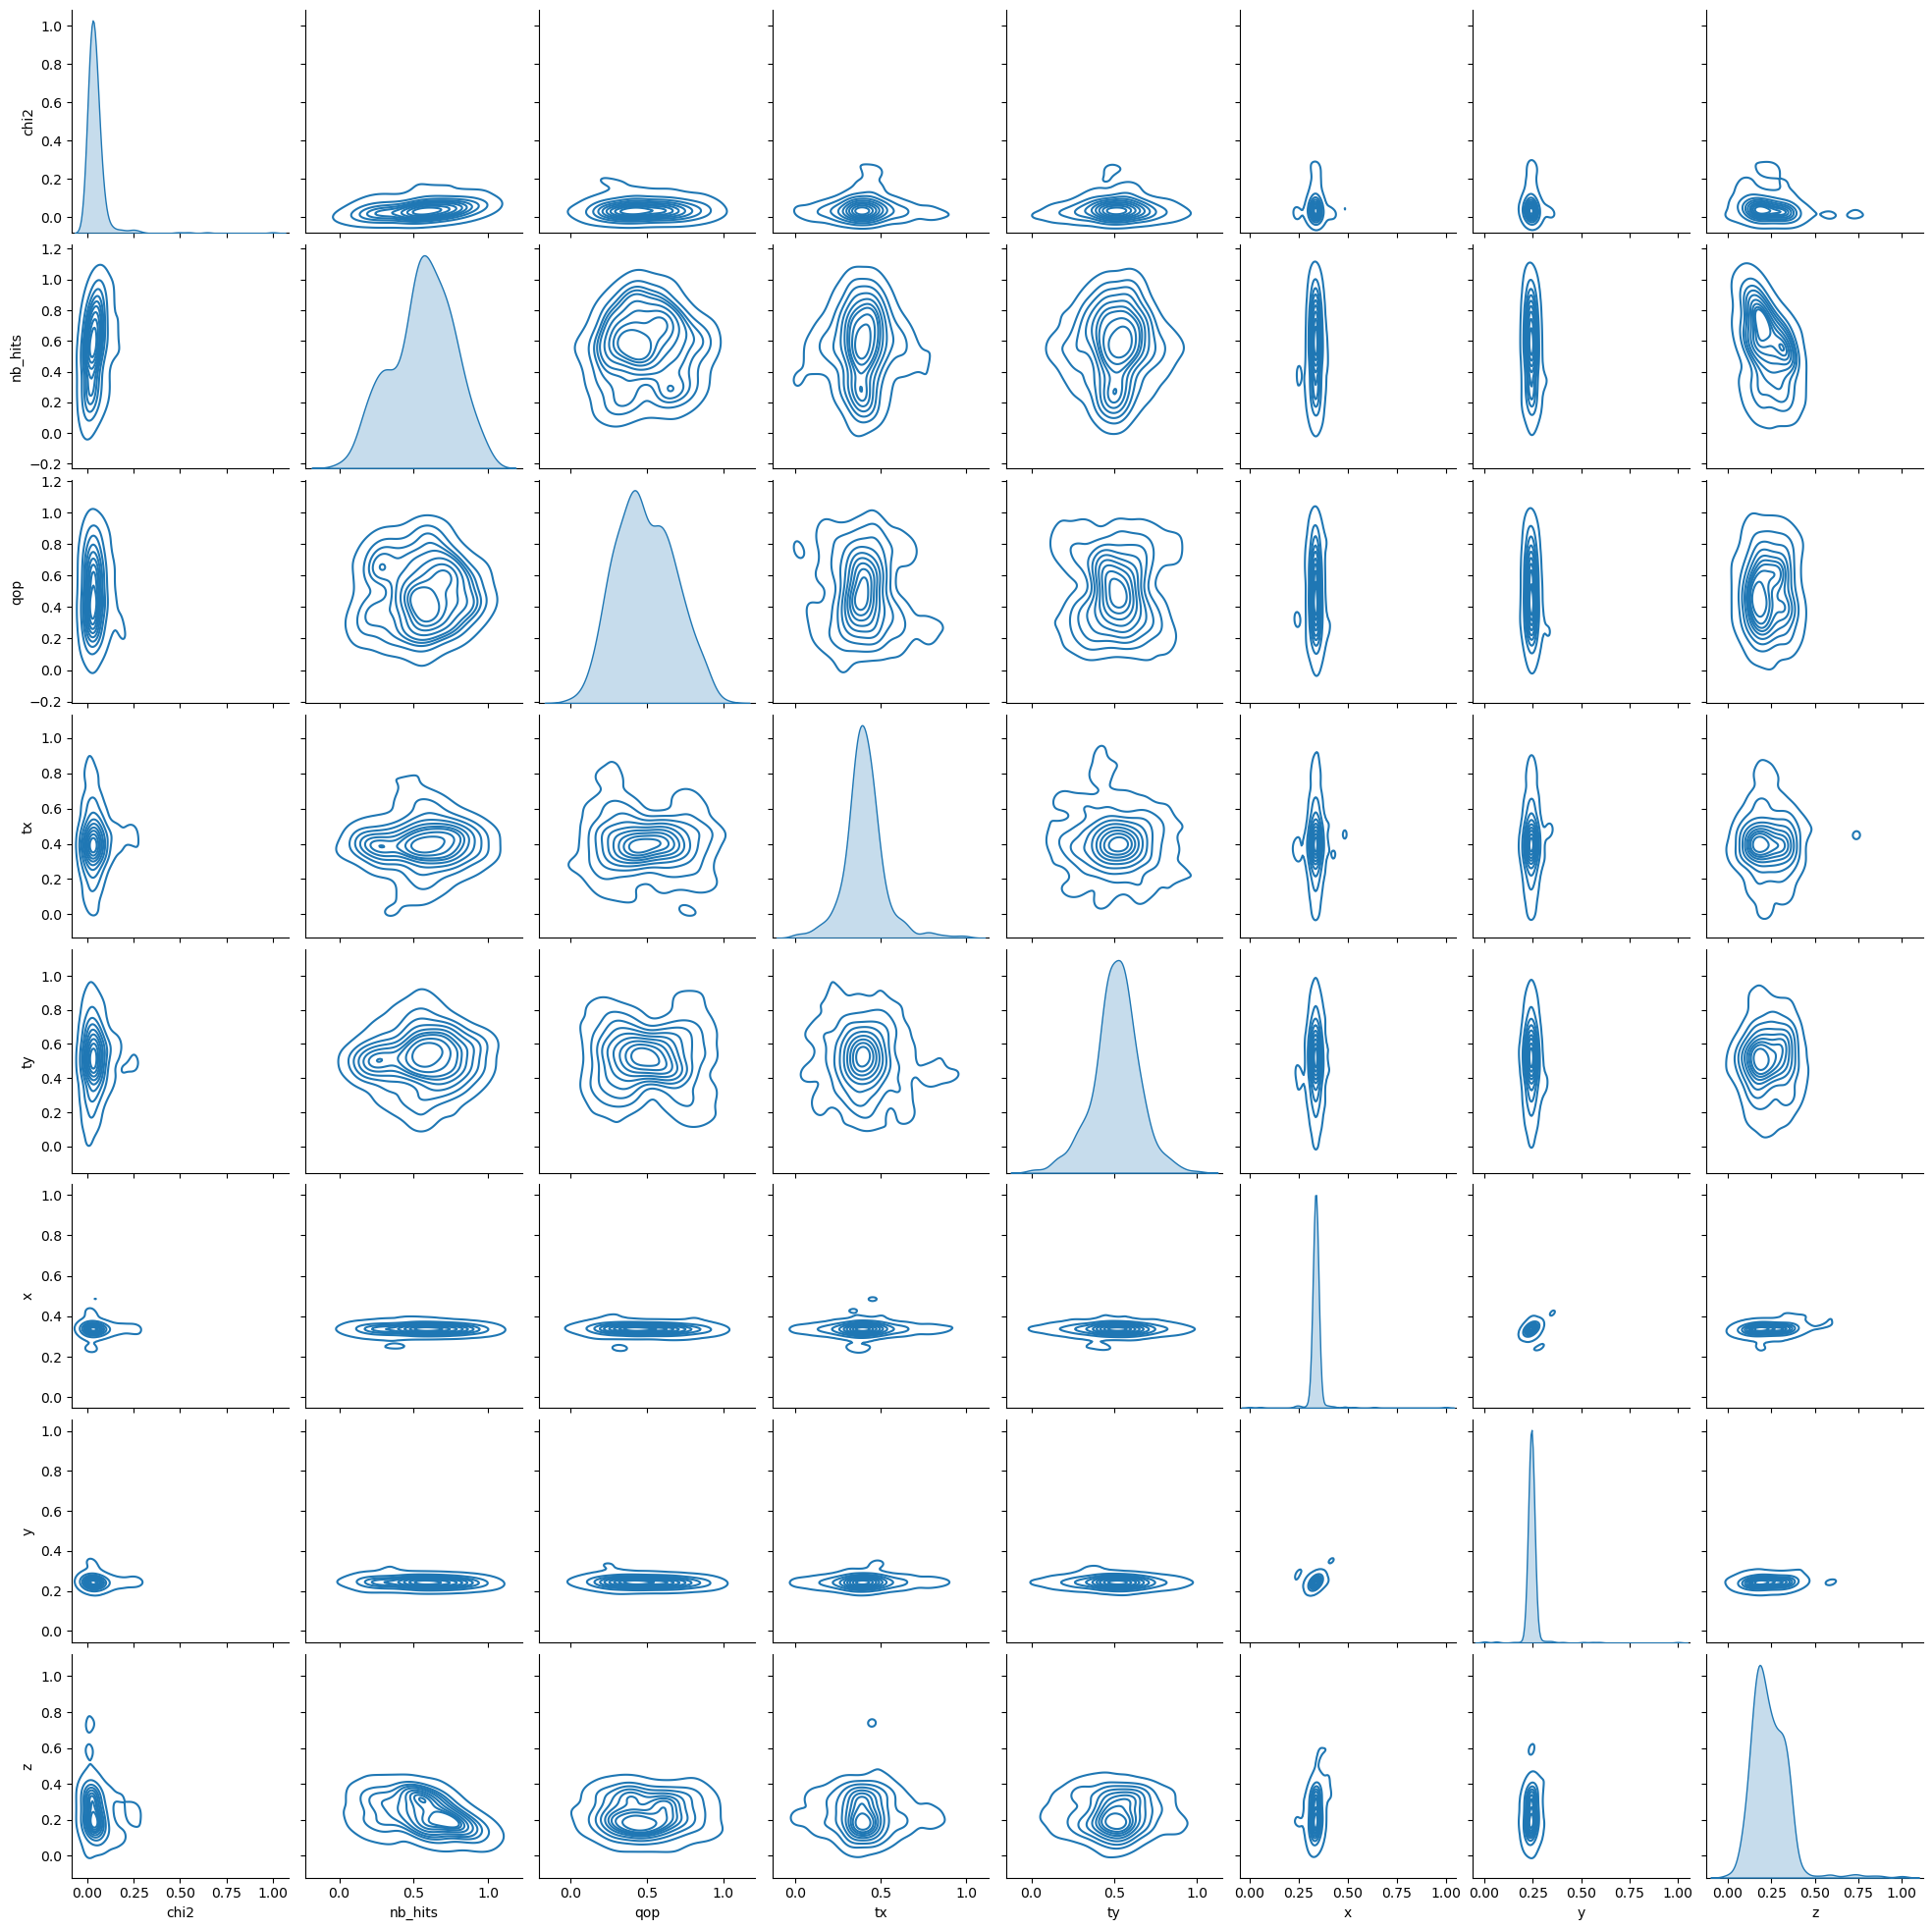

In [12]:
sns.pairplot(pd.DataFrame(x_train, columns=columns), kind='kde')

# Visualization

<Axes: >

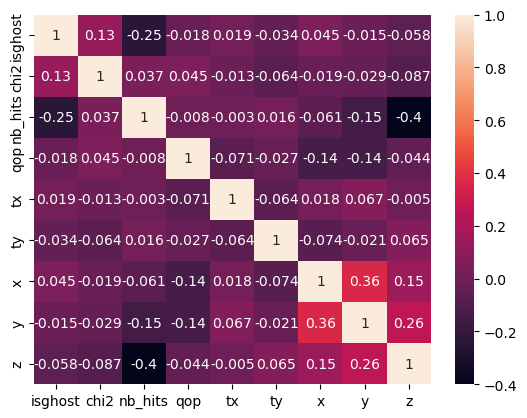

In [13]:
corr = df.corr().round(3)
sns.heatmap(corr, annot=True)

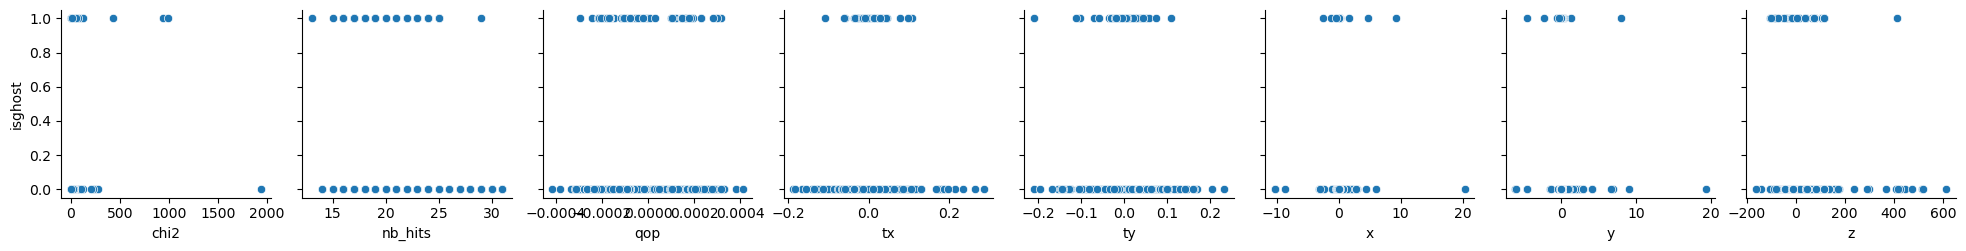

In [14]:
sns.pairplot(data=df, x_vars= df.drop(columns=target_feature).columns, y_vars=[target_feature])

plt.show()

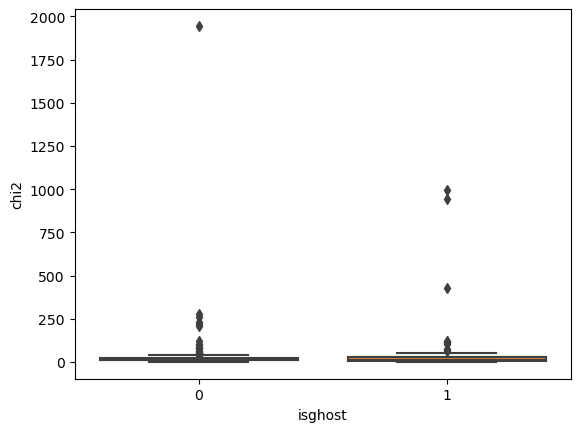

In [15]:
sns.boxplot(x=target_feature, y='chi2', data=df)

plt.show()

# Model Fitting

In [16]:
from models.AutoEncoder import Autoencoder
from models.ContractiveAutoEncoder import ContractiveAutoEncoder
from models.VariationalAutoencoder import VariationalAutoEncoder


#instantiate the contractive autoencoder
#the input dimension should match with the input features
#instead the latent dimensionis the desired compression rate
#such that higher latent_dim result in lower compression rate and more expressivity
#while instead lower latent dimension leads to less reconstruction quality
# but also less validatinon error (less model complexity)

#The latent space representation captures the most salient features of the input data
#a lower latent_dim may lead to a higher reconstruction error for anomalous inputs,
#setting latent_dim too low may also result in the loss of important information
#latent dimension should start small and then raised until diminishing returns 


#when performing anomaly detection using autoencoders these have to be trained using normal data
#such that the network learns to reproduce those instances, and that we can then perform the 
#detection using a threshold applied on the reconstruction error of any instance
input_dim = train_normal_data.shape[1]
latent_dim = 3
learning_rate = 0.001
epochs = 5

vae = VariationalAutoEncoder(input_dim=input_dim, latent_dim=latent_dim, learning_rate=learning_rate)
vae.build(input_shape=(train_normal_data.shape))
cae = ContractiveAutoEncoder(input_dim=input_dim, encoding_dim=latent_dim, lambda_= 0.01, learning_rate=learning_rate)
cae.build(input_shape=(train_normal_data.shape))
ae = Autoencoder(input_dim=input_dim, encoding_dim=latent_dim, learning_rate=learning_rate)
ae.build(input_shape=(train_normal_data.shape))


In [17]:
#start the training of the NN,
#assuming a convex loss function the higher the number of epochs the better the results will be.
#an higher batch size implies that a larger share of the training examples are processed together
#this eventually leads to fatser training and higher generalizion error (model doesn't learn underlying distribution but training data) 
history_cae, training_time_cae = cae.train(train_normal_data, epochs=epochs, batch_size=30)


Step: 0, Train Loss: 0.04472708702087402, Val Loss: 0.04622332379221916
Step: 0, Train Loss: 0.015836261212825775, Val Loss: 0.022090382874011993
Step: 0, Train Loss: 0.014081193134188652, Val Loss: 0.017714984714984894
Step: 0, Train Loss: 0.014966921880841255, Val Loss: 0.018160568550229073
Step: 0, Train Loss: 0.014056510291993618, Val Loss: 0.018167726695537567


In [18]:
history_ae, training_time_ae = ae.train(train_normal_data, epochs=epochs, batch_size=30, validation_split=0.2)

Epoch 1/5
10/10 [==============================] - 2s 48ms/step - loss: 0.0524 - val_loss: 0.0236
Epoch 2/5
10/10 [==============================] - 0s 17ms/step - loss: 0.0231 - val_loss: 0.0189
Epoch 3/5
10/10 [==============================] - 0s 15ms/step - loss: 0.0193 - val_loss: 0.0171
Epoch 4/5
10/10 [==============================] - 0s 18ms/step - loss: 0.0185 - val_loss: 0.0172
Epoch 5/5
10/10 [==============================] - 0s 16ms/step - loss: 0.0183 - val_loss: 0.0170


In [19]:
history_vae, training_time_vae = vae.train(train_normal_data, epochs=epochs, batch_size=30, validation_split=0.2)


Epoch 1/5
10/10 [==============================] - 2s 50ms/step - loss: 0.6778 - val_total_loss: 0.0000e+00
Epoch 2/5
10/10 [==============================] - 0s 9ms/step - loss: 0.6153 - val_total_loss: 0.0000e+00
Epoch 3/5
10/10 [==============================] - 0s 17ms/step - loss: 0.6009 - val_total_loss: 0.0000e+00
Epoch 4/5
10/10 [==============================] - 0s 37ms/step - loss: 0.5991 - val_total_loss: 0.0000e+00
Epoch 5/5
10/10 [==============================] - 0s 9ms/step - loss: 0.5994 - val_total_loss: 0.0000e+00


In [20]:
print("Training time AE: " + str(training_time_ae) + "training time CAE: " + str(training_time_cae) + " training time VAE: " + str(training_time_vae)) 

Training time AE: 2.504842519760132training time CAE: 1.9593441486358643 training time VAE: 2.6401548385620117


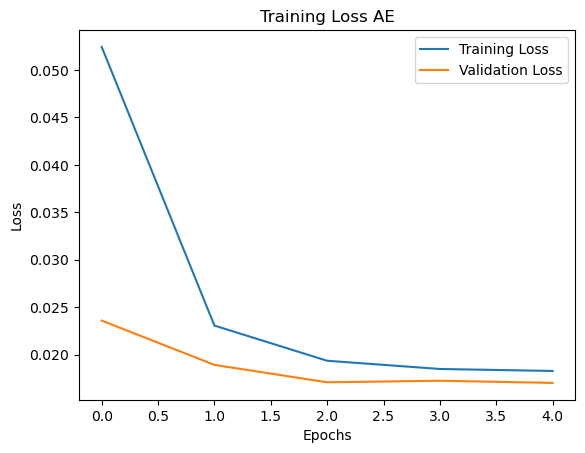

In [21]:
# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_ae.history['loss'], label='Training Loss')
plt.plot(history_ae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss AE')

# Add legend
plt.legend()

# Display the plot
plt.show()

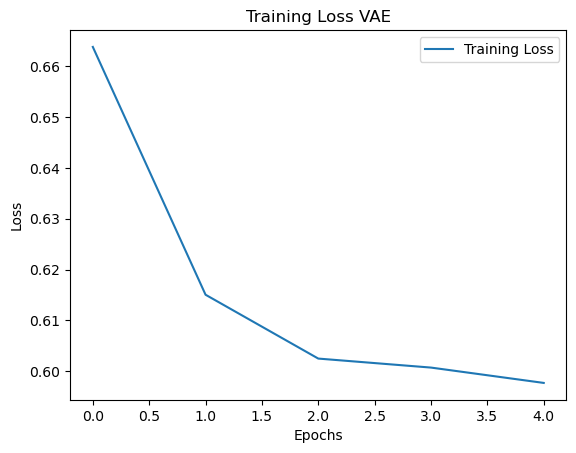

In [22]:
"""

#variational loss training and validation loss
train_losses = [item[0] for item in history_vae]
val_losses = [item[1] for item in history_vae]
epochs = range(1, len(history_cae)+1)

plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss CAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

"""


# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_vae.history['loss'], label='Training Loss')
#plt.plot(history_vae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss VAE')

# Add legend
plt.legend()

# Display the plot
plt.show()


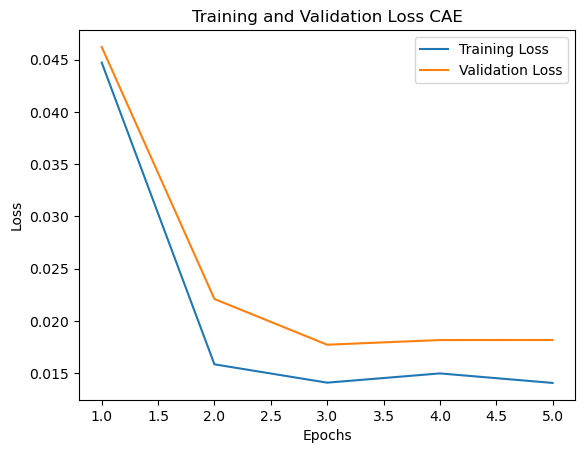

In [23]:
#contractive loss training and validation loss
train_losses = [item[0] for item in history_cae]
val_losses = [item[1] for item in history_cae]
epochs = range(1, len(history_cae)+1)

plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss CAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

12/12 [==============================] - 0s 3ms/step


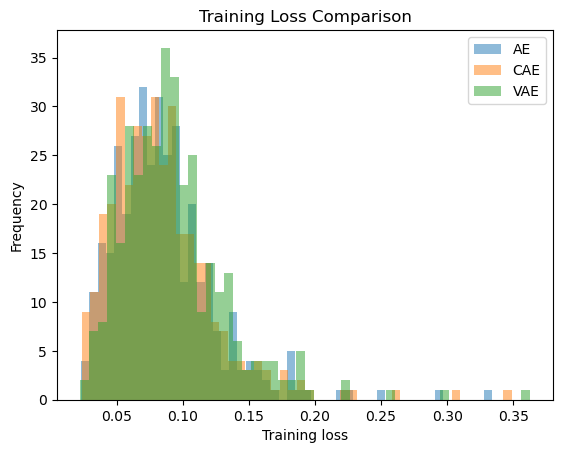

In [24]:
#MAE of the CAE over the number of samples 
cae_train_pred = cae.call(train_normal_data)
cae_mae_loss = np.mean(np.abs(cae_train_pred - train_normal_data), axis=1)

#MAE of the AE over the number of samples 
ae_train_pred = ae.predict(train_normal_data)
ae_mae_loss = np.mean(np.abs(ae_train_pred - train_normal_data), axis=1)

#MAE of the VAE over the number of samples 
vae_train_pred = vae.predict(train_normal_data)
vae_mae_loss = np.mean(np.abs(vae_train_pred - train_normal_data), axis=1)

# Plotting
plt.hist(ae_mae_loss, alpha= 0.5, label='AE', bins=50)
plt.hist(cae_mae_loss, alpha= 0.5, label='CAE', bins=50)
plt.hist(vae_mae_loss, alpha= 0.5, label='VAE', bins=50)

# Add labels and title
plt.xlabel('Training loss')
plt.ylabel('Frequency')
plt.title('Training Loss Comparison')

# Add legend
plt.legend()

# Display the plot
plt.show()

# Setting a threshold
In anomaly detection, a threshold is used to determine whether a sample is normal or anomalous based on its reconstruction error (i.e., the difference between the input and its reconstruction).

The threshold is typically set by selecting a value such that any sample with a reconstruction error above the threshold is classified as an anomaly, while any sample with a reconstruction error below the threshold is classified as normal. To come up with said thrashold we're going to take the mean and standard deviation of the residuals, and cosnidering a number of standard deviations away from the mean we're gonna find a threshold. 
The threshold needs to be set on the reconstruction for the training and not for the test as that would introduce some information on the underlying distribution of the data.

In [25]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    deviations_threshold_ae = ae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
    deviations_threshold_cae = cae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
    deviations_threshold_vae = vae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)

In [26]:
#getting 
predictions_ae = ae.find_anomalies(x_test, deviations_threshold_ae)

#looking at the metrics for anomaly detection so far
ae.classification_metrics(y_test, predictions_ae, printing=True)

4/4 [==============================] - 0s 5ms/step
Accuracy: 0.6300
Precision: 0.1860
Recall: 0.8000
F1-Score: 0.3019
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.61      0.75        90
           1       0.19      0.80      0.30        10

    accuracy                           0.63       100
   macro avg       0.58      0.71      0.53       100
weighted avg       0.89      0.63      0.70       100



In [27]:
#getting the predictions
predictions_cae = cae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
cae.classification_metrics(y_test, predictions_cae, printing=True)

Accuracy: 0.5500
Precision: 0.1698
Recall: 0.9000
F1-Score: 0.2857
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.51      0.67        90
           1       0.17      0.90      0.29        10

    accuracy                           0.55       100
   macro avg       0.57      0.71      0.48       100
weighted avg       0.90      0.55      0.63       100



In [28]:
#getting the predictions
predictions_vae = vae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
vae.classification_metrics(y_test, predictions_vae, printing=True)

4/4 [==============================] - 0s 3ms/step
Accuracy: 0.6100
Precision: 0.1778
Recall: 0.8000
F1-Score: 0.2909
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.59      0.73        90
           1       0.18      0.80      0.29        10

    accuracy                           0.61       100
   macro avg       0.57      0.69      0.51       100
weighted avg       0.89      0.61      0.69       100



# Performance 

Here we're going to take into consideration some metrics, with their relevant visualization, of the models' performance in the anomaly detectino task. 
As first step we're so going to look into the ROC curve, that is a plot of the "False positive rate" against the "True positive rate". The curve therefore aims at 
describing the strength of a classifier, such that the more the curve appriaches the top left corner the strongest the method is. While instead if the curve approaches the 
line y = x, or the corss-section of the plane, the more the classifier approaches a random one. 

In [29]:
def plot_ROC(y_test, predictions, name):

    # find the roc curve for the actual target values and the predictions
    fpr, tpr, _ = roc_curve(y_test, predictions)
    roc_auc = auc(fpr, tpr)

    #finding the Youden's J statistic, it's a metric that describes the power of classifier
    #where 0 is random guesser and 1 is a perfect classifier
    j_statistic = tpr - fpr
    print("the j_statistic is " + str(j_statistic[1]))

    #plotting the roc curve with the best trehsold against the random predictor
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + name)
    plt.legend(loc="lower right")
    plt.show()


the j_statistic is 1.0


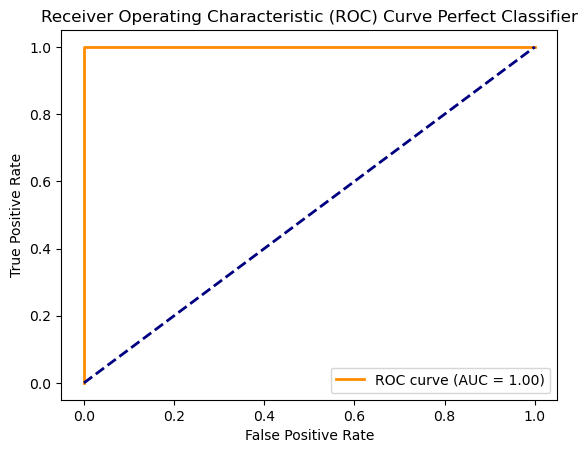

In [30]:
plot_ROC(y_test=y_test, predictions=y_test, name="Perfect Classifier")

the j_statistic is 0.41111111111111115


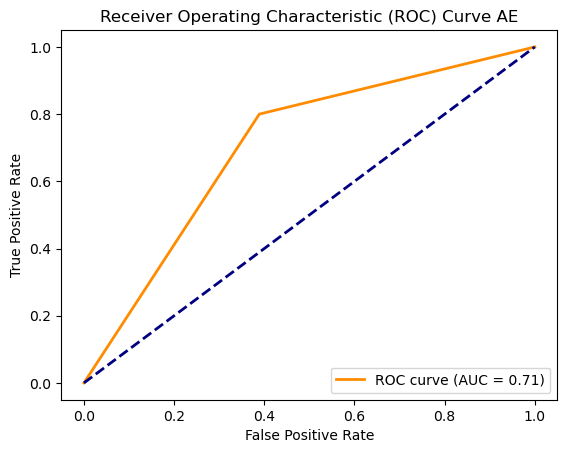

In [31]:
plot_ROC(y_test=y_test, predictions=predictions_ae, name="AE")

the j_statistic is 0.41111111111111115


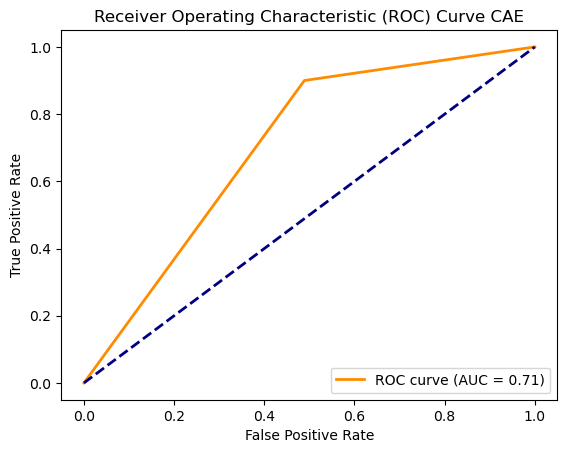

In [32]:
plot_ROC(y_test=y_test, predictions=predictions_cae, name="CAE")

the j_statistic is 0.38888888888888895


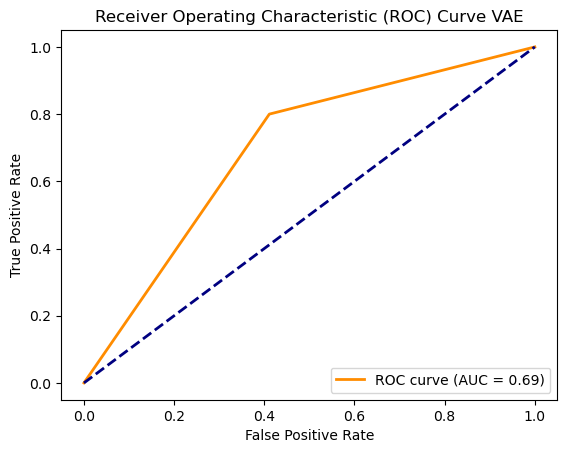

In [33]:
plot_ROC(y_test=y_test, predictions=predictions_vae, name="VAE")

### Precision recall curve

This type of plot is made to better understand the performance of the models, given an high class imbalance. Precision indicates the proportion of correct positive identifications. Recall instead the proportion of actual positives that has been identified correctly. A perfect classifier is a squashed against the top right corner. A no-skill model will instead have a precision equal to the % of the positive class. 

https://analyticsindiamag.com/complete-guide-to-understanding-precision-and-recall-curves/

In [34]:
def pr_curve(y_true, predictions, name):

    precision, recall, _ = precision_recall_curve(y_true, predictions)
    #find the no_skill classifier line
    no_skill_precision = np.sum(y_true) / len(y_true)

    # plot the precision-recall curve
    plt.plot(recall, precision, color="darkorange")
    plt.axhline(y=no_skill_precision, color='navy', linestyle='--', label='No Skill')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve ' + name)
    plt.show()

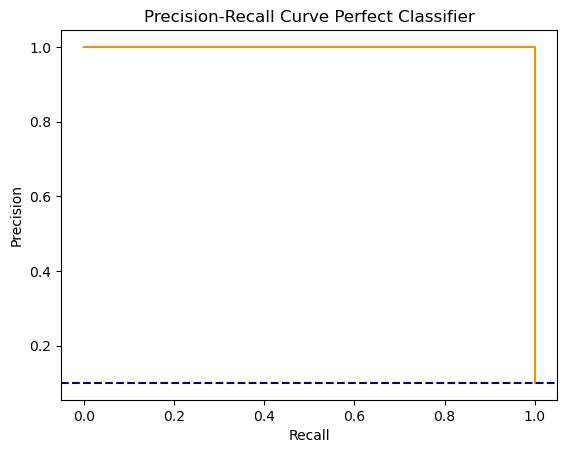

In [35]:
pr_curve(y_true=y_test, predictions=y_test, name="Perfect Classifier")

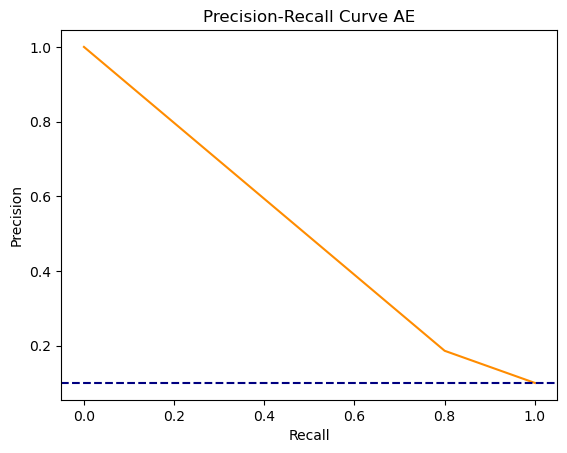

In [36]:
pr_curve(y_test, predictions_ae, name="AE")

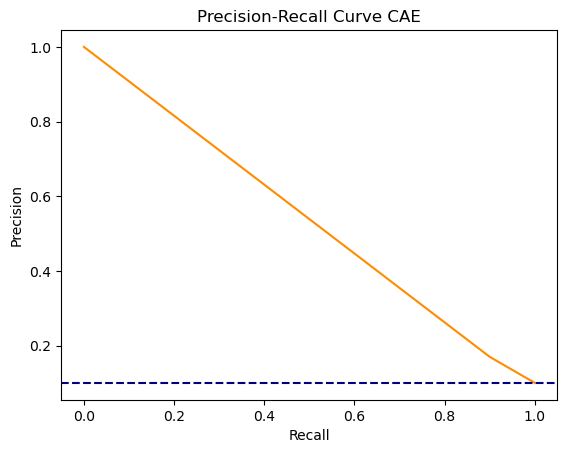

In [37]:
pr_curve(y_test, predictions_cae, name="CAE")

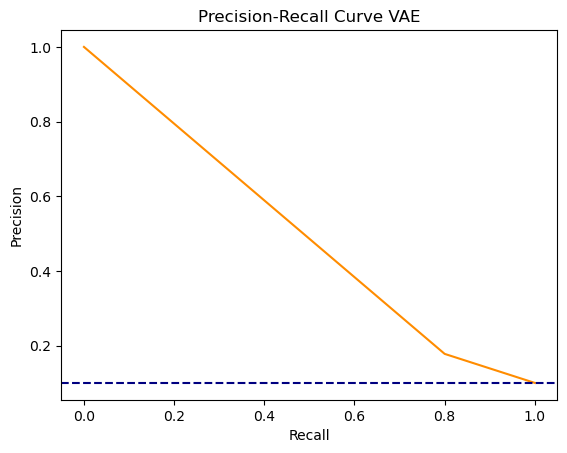

In [38]:
pr_curve(y_test, predictions_vae, name="VAE")

### Latent space plot.

Here we investigate how the ghost and normal samples are separated by the different models in the latent space. Eventually we would like to have the ghost tracks clustered together and so the normal ones. The normal tracks will be shown in green and the ghost tracks in red. 

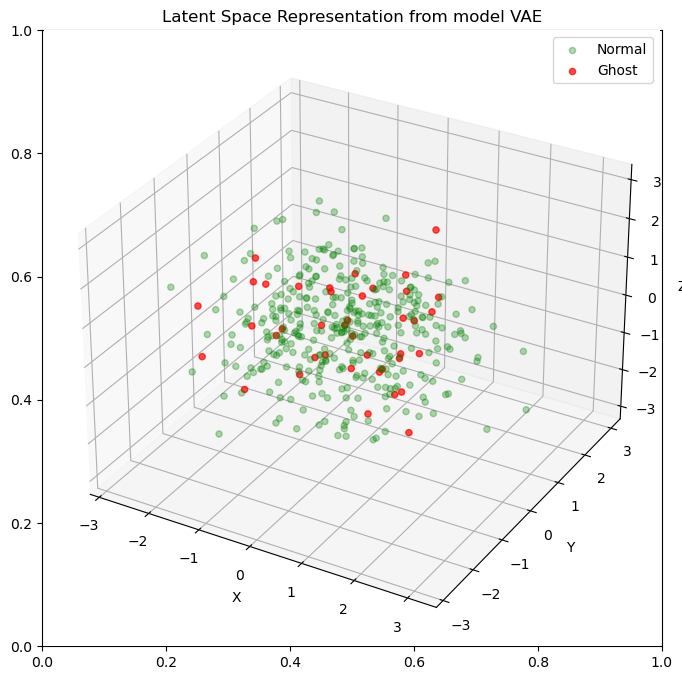

In [39]:
def plot_latent(name, model):
    
    data = tf.convert_to_tensor(x_train)
    latent_representation = model.encode(data)

    #different models have different ways of outputting the encoded data
    if tf.is_tensor(latent_representation):
        latent_representation = latent_representation.numpy()


    #accessing the value coordinates for the encoded data
    X = latent_representation[:,0]
    y = latent_representation[:,1]
    z = latent_representation[:,2]
    
    #plotting the data points in a 3D space
    #the green points correspond to normal instances
    #the red points correspond to the anomlaous data
    fig, ax = plt.subplots(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(X[y_train==0], y[y_train==0], z[y_train==0], c='g', alpha=0.3, label='Normal')
    ax.scatter(X[y_train==1], y[y_train==1], z[y_train==1], c='r', alpha=0.7, label='Ghost')

    # labeling
    ax.legend(loc='best')
    ax.set_title('Latent Space Representation from model ' + name)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    # saving & displaying
    #plt.savefig('latent_representation_3d');
    plt.show()

plot_latent("VAE", vae)

13/13 [==============================] - 0s 3ms/step


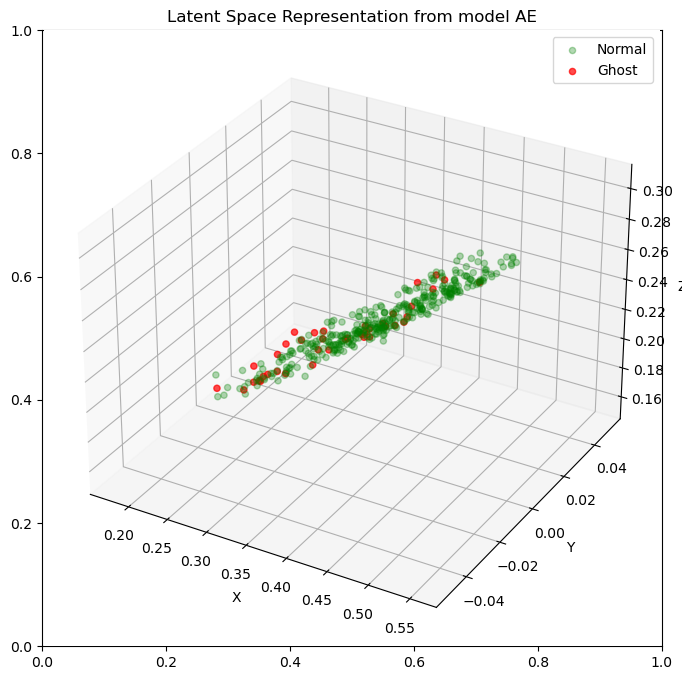

In [40]:
plot_latent("AE", ae)

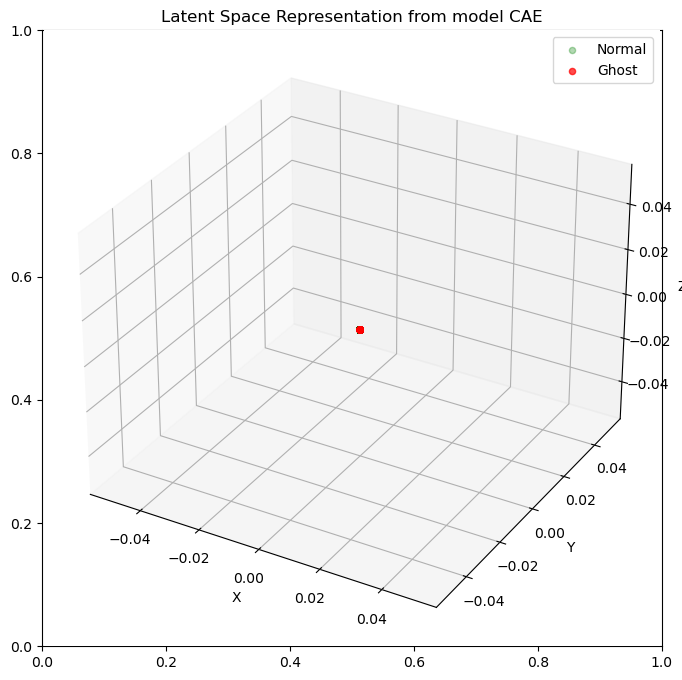

In [41]:
plot_latent("CAE", cae)

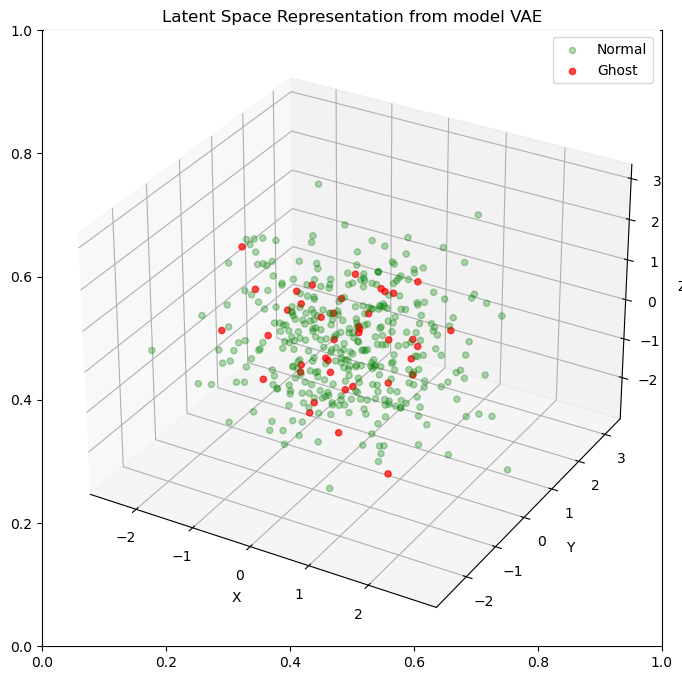

In [42]:
plot_latent("VAE", vae)

### Reconstruction error 

Here I'm plotting the reconstruction error distribution of the different methods so to have a overview of their "strength" and point out eventual discrepancies.

In [43]:
def plot_reconstruction_error(errors): 
    
    normal = errors[y_test==0]
    ghost = errors[y_test==1]

    _, ax = plt.subplots(figsize=(8,8))

    ax.hist(normal, bins=50, density=True, label="Normal", alpha=0.6)
    ax.hist(ghost, bins=50, density=True, label="Ghost", alpha=0.6)
    ax.set_xlabel("Frequency")
    ax.set_ylabel("Reconstruction loss")

    plt.title("(Normalized) Distribution of the Reconstruction Loss")
    
    plt.legend()
    plt.show()

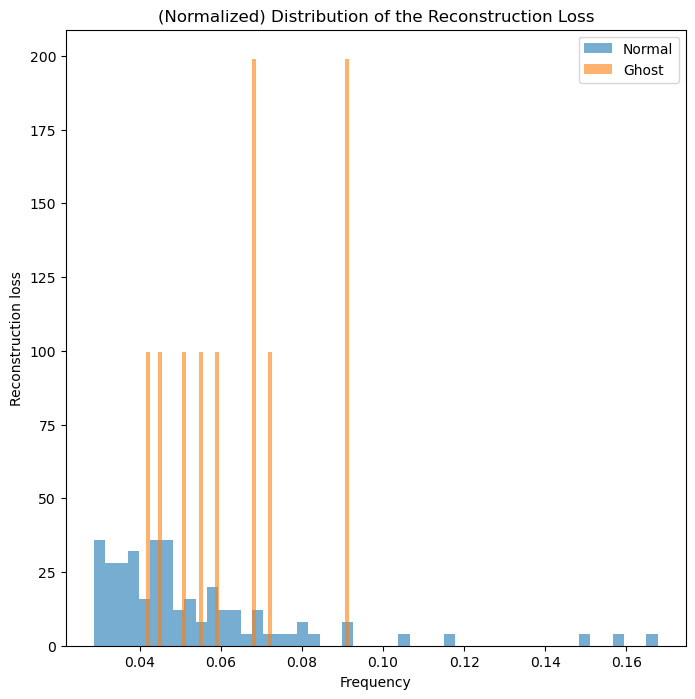

In [44]:
reconstruction_ae = ae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_ae, 2), axis=1)
plot_reconstruction_error(mse)

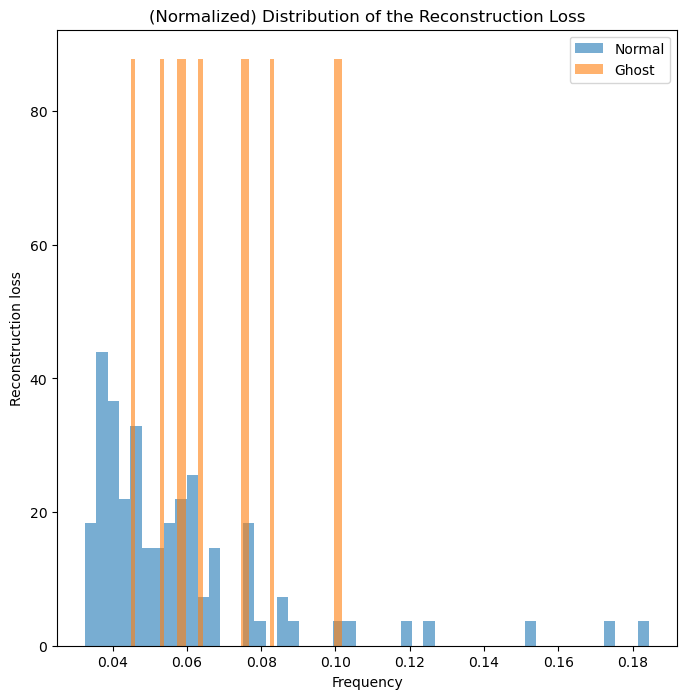

In [45]:
reconstruction_cae = cae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_cae, 2), axis=1)
plot_reconstruction_error(mse)

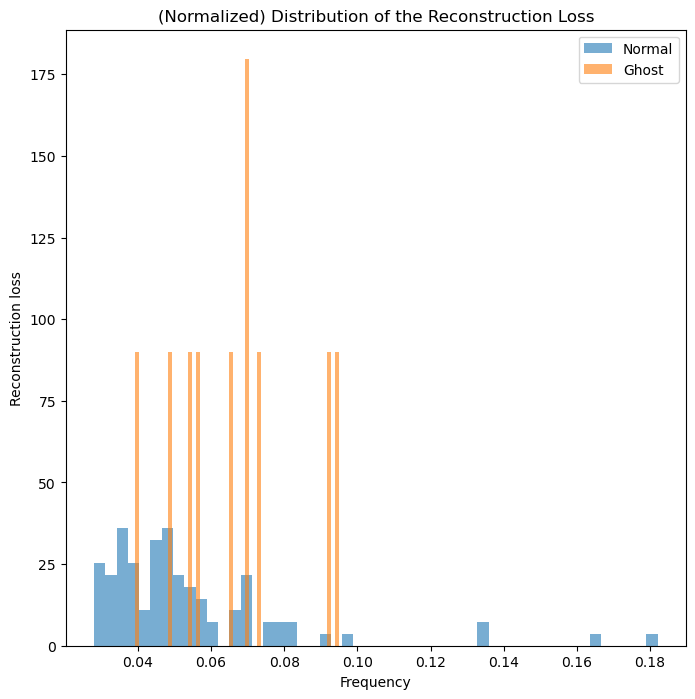

In [46]:
reconstruction_vae = vae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_vae, 2), axis=1)
plot_reconstruction_error(mse)

# ALAD
#### First we're gonna transfer the weights of the encoder part of the autoencoder to the generator of the ALAD

In [47]:
from models.ALAD import ALAD
from sklearn.metrics import accuracy_score


latent_dim = train_normal_data.shape[1]
alad = ALAD(input_dim=train_normal_data.shape[1], latent_dim=latent_dim, learning_rate=0.003)

# the model needs to be trained on the normal data to learn the underlying distribution
alad.train(train_normal_data, epochs=5, batch_size=64)

predictions = alad.predict(x_test)


# here we're relying on a threshold set just based on the percentile
threshold = alad.find_best_deviations_threshold(train_normal_data, x_test, y_test)
threshold = np.percentile(predictions, 90)

predictions = np.where(predictions > threshold, 1, 0)

#print the accuracy and the roc
accuracy = accuracy_score(y_test, predictions)
print('Accuracy of anomaly detection: {:.2f}%'.format(accuracy * 100))

Epoch: 0,  Encoder Loss: 0.21342429518699646, Decoder Loss: 0.009644832462072372, Disc_xx Loss: 8.625090413261205e-05, Disc_xz Loss: 0.22306913137435913, Disc_zz Loss: 1.3304368257522583
Epoch: 1,  Encoder Loss: 0.005867185071110725, Decoder Loss: 5.519530077435775e-07, Disc_xx Loss: 1.4413469450265256e-22, Disc_xz Loss: 0.005867736879736185, Disc_zz Loss: 0.5856407880783081
Epoch: 2,  Encoder Loss: 7.731110963504761e-05, Decoder Loss: 2.616047569542479e-12, Disc_xx Loss: 0.0, Disc_xz Loss: 7.731110963504761e-05, Disc_zz Loss: 0.0005573006928898394
Epoch: 3,  Encoder Loss: 2.2845183593744878e-06, Decoder Loss: 8.703205124514336e-23, Disc_xx Loss: 0.0, Disc_xz Loss: 2.2845183593744878e-06, Disc_zz Loss: 0.011624269187450409
Epoch: 4,  Encoder Loss: 1.781509126885794e-07, Decoder Loss: 1.7968845670801545e-23, Disc_xx Loss: 0.0, Disc_xz Loss: 1.781509126885794e-07, Disc_zz Loss: 0.16988040506839752
Accuracy of anomaly detection: 10.00%


Accuracy: 0.1000
Precision: 0.1000
Recall: 1.0000
F1-Score: 0.1818
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        90
           1       0.10      1.00      0.18        10

    accuracy                           0.10       100
   macro avg       0.05      0.50      0.09       100
weighted avg       0.01      0.10      0.02       100

the j_statistic is 0.0


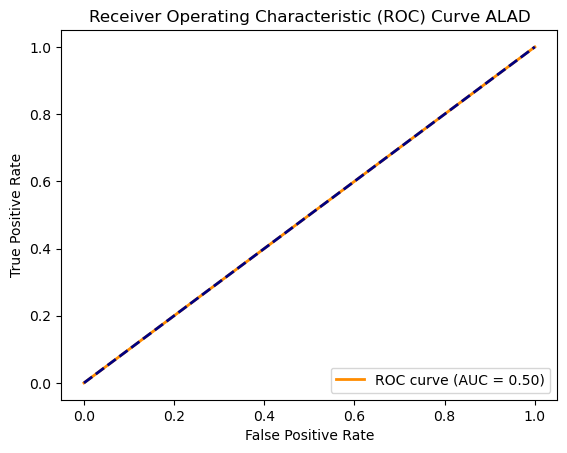

In [48]:
alad.classification_metrics(y_test, predictions, printing=True)
plot_ROC(y_test=y_test, predictions=predictions, name="ALAD")

# Isolation forest

Precision: 0.1111111111111111
Recall: 0.25
F1-score: 0.15384615384615383
ROC AUC: 0.41711956521739135
the j_statistic is 0.07608695652173914


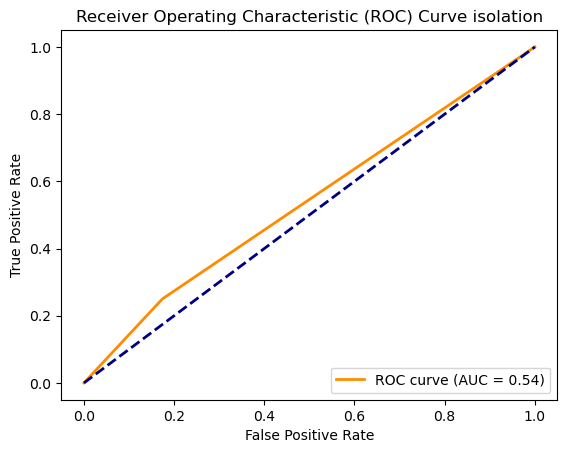

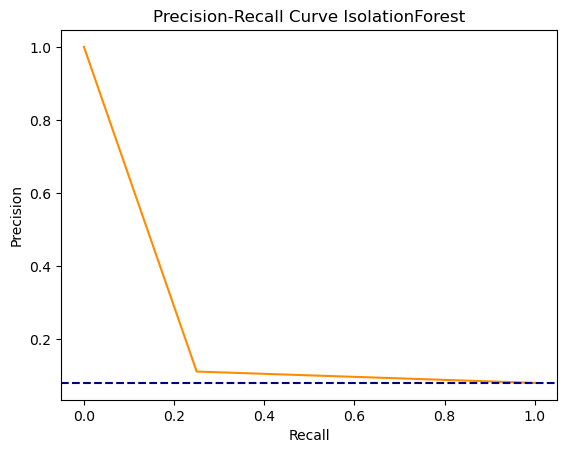

In [49]:
#this is an unsupervised learning method,
#in fact it is fed both normal and anomalous data
#during the training phase it learns from both normal and anomalous

from sklearn.ensemble import IsolationForest

X = df.drop(target_feature, axis=1)
y = df[target_feature]

X_train, X_test, y_train, y_test = train_test_split(X.values, y.values, test_size=0.2, random_state=42)


x_train = (X_train - X_train.mean()) / X_train.std()
x_test = (x_test - X_train.mean()) / X_train.std()

#now moving the data to a fixed range of values 
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)

# trainig phase
clf = IsolationForest(n_estimators=10000, max_samples='auto', contamination=0.2, random_state=42)
clf.fit(X_train)

anomaly_scores = clf.decision_function(X_test)


y_pred = clf.predict(X_test)
y_pred = [1 if pred == -1 else 0 for pred in y_pred]



from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, anomaly_scores)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC AUC:", roc_auc)


plot_ROC(y_test, y_pred, "isolation")
pr_curve(y_test, y_pred, name="IsolationForest")

# One-class SVM

the j_statistic is 0.0


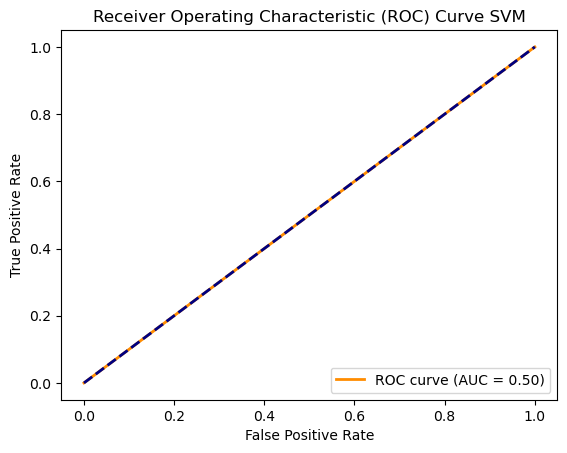

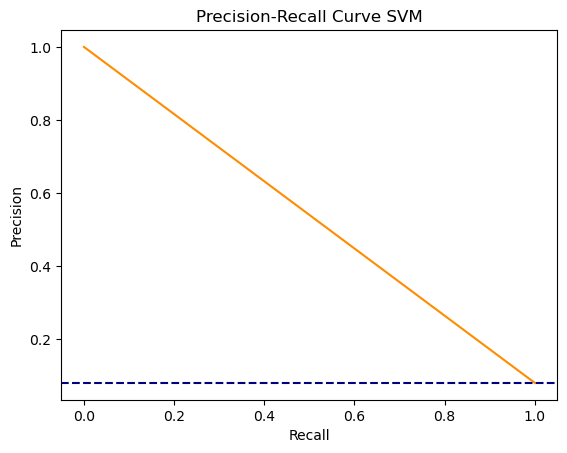

In [50]:

from sklearn import svm

# train the one class support vector machine
# nu specifies the upper bound on the tracks to be 
# classified as anomalies, it's a percentage 
# gamma controls the "smoothness" of the decision curve
# smaller gamma implies less overfitting but also lack of complexity...
clf = svm.OneClassSVM(nu=0.1, kernel="rbf", gamma=0.9)
clf.fit(train_normal_data)

# predict if the test instaces are anomalies or not
#Returns -1 for outliers and 1 for inliers.
y_pred = clf.predict(x_test)  


y_pred = [1 if pred == -1 else 0 for pred in y_pred]


# find the ROC curve 
plot_ROC(y_test, y_pred, "SVM")
pr_curve(y_test, y_pred, name="SVM")


# Recap

Finally comapring all the models' metrics in one go!

In [51]:
#plot all the training losses together

In [52]:
def get_data():

    train_normal_data, _, _, x_test, y_test = get_normal_data(df)
    _, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)

    return train_normal_data, x_test, y_test

In [53]:
#change this a bit

def avgNestedLists(nested_vals):
    """
    Averages a 2-D array and returns a 1-D array of all of the columns
    averaged together, regardless of their dimensions.
    """
    output = []
    maximum = 0
    for lst in nested_vals:
        if len(lst) > maximum:
            maximum = len(lst)
    for index in range(maximum): # Go through each index of longest list
        temp = []
        for lst in nested_vals: # Go through each list
            if index < len(lst): # If not an index error
                temp.append(lst[index])
        output.append(np.nanmean(temp))
    return output

In [54]:
import numpy as np
from sklearn.metrics import roc_curve, auc
from scipy import stats


def mean_and_confidence(model, threshold_function, alpha=0.95, iterations=5, epochs=2):
   

    #initialize all the containers for teh metrics to track
    list_fpr = []
    list_tpr = []
    list_auc = []

    #precision and recall will be used for 
    #the curve but also as general parameters 
    list_precision_curve = []
    list_recall_curve = []

    #classification metrics 
    list_accuracy = []
    list_precision = []
    list_recall = []
    list_f1 = []

    list_training_time = []


    model.save_weights('saved_weights/my_model_' + model.model_name)

    # Perform 100 iterations
    for _ in range(iterations):

        x_train, x_test, y_test = get_data()
        history, training_time = model.train(x_train, epochs=epochs, batch_size=30, validation_split=0.2)
        ###time each model 
        threshold = threshold_function(x_train, x_test, y_test)
        predictions = model.find_anomalies(x_test, threshold)
        accuracy, precision, recall, f1 = model.classification_metrics(y_test, predictions)

        #re-set all the trainable variables of the model
        model.load_weights('saved_weights/my_model_' + model.model_name)
        
        fpr_ae, tpr_ae, _ = roc_curve(y_test, predictions)
        auc_ae = auc(fpr_ae, tpr_ae)
        list_fpr.append(fpr_ae)
        list_tpr.append(tpr_ae)
        list_auc.append(auc_ae)

        precision_curve, recall_curve, _ = precision_recall_curve(y_test, predictions)
        list_precision_curve.append(precision_curve)
        list_recall_curve.append(recall_curve)


        list_accuracy.append(accuracy)
        list_precision.append(precision)
        list_recall.append(recall)
        list_f1.append(f1)

        list_training_time.append(training_time)

    #roc_curve can return different sized arrays
    #this means that ther needs to be a custom function
    #to compute the mean 
    avg_fpr = avgNestedLists(list_fpr)
    avg_tpr = avgNestedLists(list_tpr)
    avg_precision_curve = avgNestedLists(list_precision_curve)
    avg_recall_curve = avgNestedLists(list_recall_curve)
    avg_acc = np.mean(list_accuracy)
    avg_rec = np.mean(list_recall)
    avg_pre = np.mean(list_precision)
    avg_f1 = np.mean(list_f1)
    avg_time = np.mean(list_training_time)
    avg_auc = np.mean(list_auc)


    #standard deviations
    accuracy_std = np.std(list_accuracy)
    precision_std = np.std(list_precision)
    recall_std = np.std(list_recall)
    f1_std = np.std(list_f1)
    training_time_std = np.std(list_training_time)
    auc_std = np.std(list_auc)

    #how to take the "mean curve"  
    interval_acc = stats.t.interval(alpha=alpha, loc=np.mean(list_accuracy), df=len(list_accuracy)-1, scale=stats.sem(list_accuracy))
    interval_rec = stats.t.interval(alpha=alpha, loc=np.mean(list_recall), df=len(list_recall)-1, scale=stats.sem(list_recall))
    interval_pre = stats.t.interval(alpha=alpha, loc=np.mean(list_precision), df=len(list_precision)-1, scale=stats.sem(list_precision))
    interval_f1 = stats.t.interval(alpha=alpha, loc=np.mean(list_f1), df=len(list_f1)-1, scale=stats.sem(list_f1))
    interval_time = stats.t.interval(alpha=alpha, loc=np.mean(list_training_time), df=len(list_training_time)-1, scale=stats.sem(list_training_time))
    interval_auc = stats.t.interval(alpha=alpha, loc=np.mean(list_auc), df=len(list_auc)-1, scale=stats.sem(list_auc))

    plt.plot(avg_fpr, avg_tpr)
    plt.plot(avg_fpr, avg_tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % avg_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + model.model_name)
    plt.legend(loc="lower right")
    plt.savefig('images/Average ROC ' + model.model_name)
    plt.close()

    plt.plot(avg_precision_curve, avg_recall_curve)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.savefig('images/Average Precision Recall ' + model.model_name)
    plt.close()


    averages = {
        "Average FPR": avg_fpr,
        "Average TPR": avg_tpr,
        "Average precision curve": avg_precision_curve,
        "Average recall curve": avg_recall_curve,
        "Average accuracy": avg_acc,
        "Average recall": avg_rec,
        "Average precision": avg_pre,
        "Average F-1": avg_f1,
        "Average training time": avg_time,
        "Average AUC": avg_auc,
        }
    
    sigmas = {
        "STD accuracy": accuracy_std,
        "STD recall": recall_std,
        "STD precision": precision_std,
        "STD F-1": f1_std,
        "STD training time": training_time_std,
        "STD AUC": auc_std,
    }
    
    intervals = {
        "Interval accuracy": interval_acc,
        "Interval recall": interval_rec,
        "Interval precision": interval_pre,
        "Interval F-1": interval_f1,
        "Interval training time": interval_time,
        "Interval AUC": interval_auc,
        }
    
    return averages, intervals, sigmas


In [55]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    averages_ae, intervals_ae, _ = mean_and_confidence(ae, ae.find_best_deviations_threshold, alpha=0.95)
    averages_cae, intervals_cae, _ = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95)
    averages_vae, intervals_vae, _ = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95)

In [56]:
def roc_curve_models(avg_ae, avg_cae, avg_vae, fun_name, avg_alad=None):

    fpr_ae = avg_ae["Average FPR"]
    tpr_ae = avg_ae["Average TPR"]
    fpr_cae = avg_cae["Average FPR"]
    tpr_cae = avg_cae["Average TPR"]
    fpr_vae = avg_vae["Average FPR"]
    tpr_vae = avg_vae["Average TPR"]

    auc_ae = avg_ae["Average AUC"]
    auc_cae = avg_cae["Average AUC"]
    auc_vae = avg_vae["Average AUC"]
    #auc_alad = averages_alad["Average AUC"]

    """"
    fpr_alad = avg_alad["Average FPR"]
    tpr_alad = avg_alad["Average TPR"]
    """


    x = np.linspace(0, 1, 10)

    # Compute y values (y = x)
    y = x

    # Plot the diagonal dotted line
    plt.plot(x, y, linestyle=':', color='purple')

    plt.plot(fpr_ae, tpr_ae, label='AE (AUC = {})'.format(round(auc_ae, 2)))
    plt.plot(fpr_cae, tpr_cae, label='CAE (AUC = {})'.format(round(auc_cae, 2)))
    plt.plot(fpr_vae, tpr_vae, label='VAE (AUC = {})'.format(round(auc_vae, 2)))
    """""
    plt.plot(fpr_alad, tpr_alad, label='ALAD (AUC = {auc_alad:.2f})')"""

    # Adding labels and legends
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.text(1.05, 0.5, fun_name, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.legend()
    plt.savefig('images/All models ROC')

    # Display the plot
    plt.show()

In [57]:
def pr_models(avg_ae, avg_cae, avg_vae, fun_name, avg_alad=None):    
    #plot all the precision-recall losses together
    precision_ae, recall_ae, = avg_ae["Average precision curve"], avg_ae["Average recall curve"]
    precision_cae, recall_cae, = avg_cae["Average precision curve"], avg_cae["Average recall curve"]
    precision_vae, recall_vae, = avg_vae["Average precision curve"], avg_vae["Average recall curve"]



    # plot the precision-recall curve
    plt.plot(recall_ae, precision_ae, color='blue', label='AE')
    plt.plot(recall_cae, precision_cae, color='red', label='CAE')
    plt.plot(recall_vae, precision_vae, color='green', label='VAE')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.text(1.05, 0.5, fun_name, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.savefig('images/All models P-R')
    plt.show()

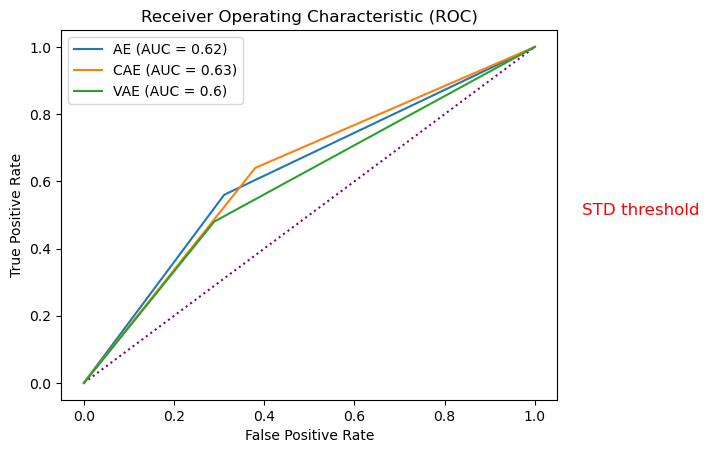

In [58]:
roc_curve_models(averages_ae, averages_cae, averages_vae, "STD threshold")

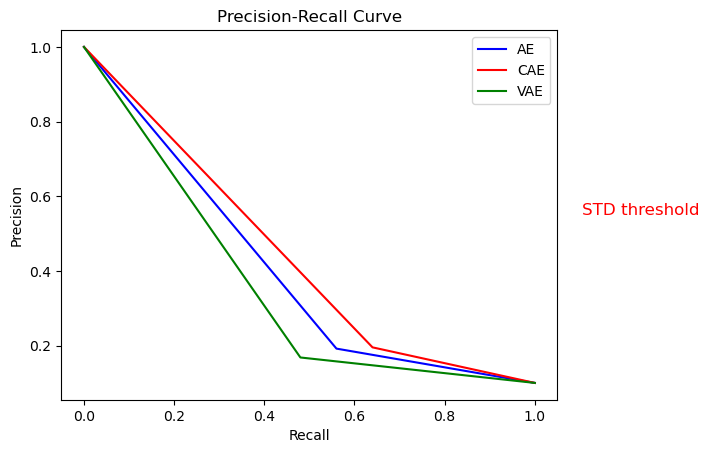

In [59]:
pr_models(averages_ae, averages_cae, averages_vae, "STD threshold")

In [60]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):
    #test different threshold function 
    averages_ae, intervals_ae, _ = mean_and_confidence(ae, ae.find_best_percentile_threshold, alpha=0.95)
    averages_cae, intervals_cae, _ = mean_and_confidence(cae, cae.find_best_percentile_threshold, alpha=0.95)
    averages_vae, intervals_vae, _ = mean_and_confidence(vae, vae.find_best_percentile_threshold, alpha=0.95)

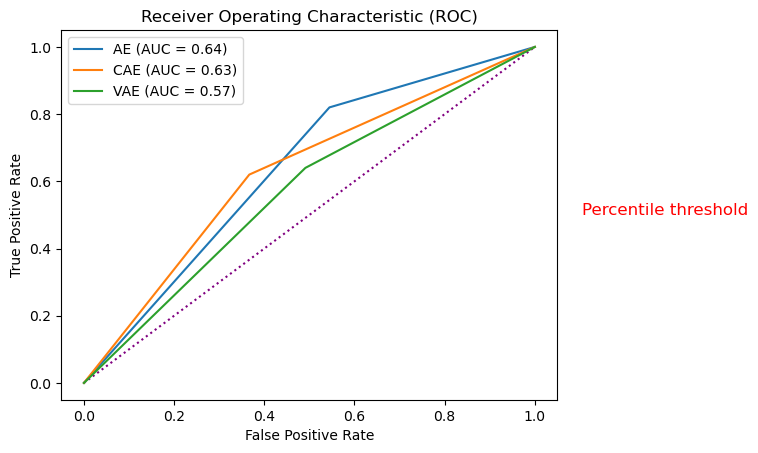

In [61]:
roc_curve_models(averages_ae, averages_cae, averages_vae, "Percentile threshold")

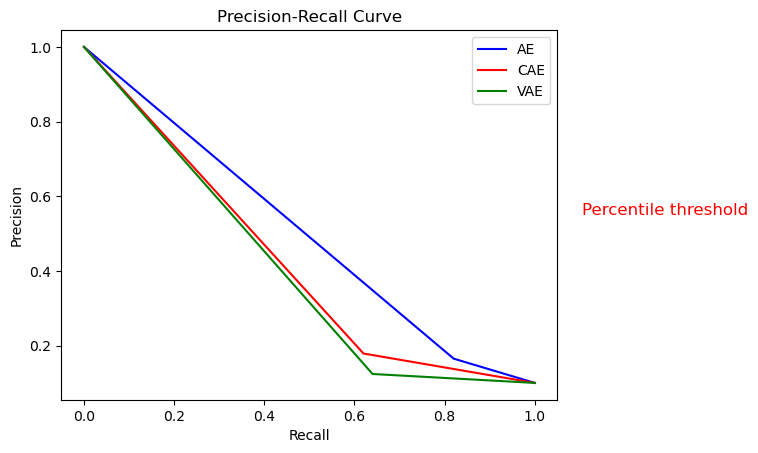

In [62]:
pr_models(averages_ae, averages_cae, averages_vae, "Percentile threshold")

It seems from these experiments that the what works best to determine the threshold for anomalies is indeed the "standard deviations method". The results from it infact dominate the ones from the "percentile method". 

# Transfer learning

Make only the AE learn by itself... Then compare the results of the transfer-learned models aginst the ones collected from training each on its own. 

In [63]:
def transfer_weights(target_model, is_alad=False):


    #this is to check if the model is VAE
    #if so we want to skip the first layer 
    #for encoder and decoder, as it's an Input layer
    #not shared by the other networks
    
    target_encoder_layers = target_model.layers
    if target_model.name == "VAE":
        target_encoder_layers = target_model.layers[1:]

    target_decoder_layers = target_model.layers
    if target_model.name == "VAE":
        target_decoder_layers = target_model.layers[1:]

    #go throught the encoer weights 
    for source_layer, target_layer in zip(ae.encoder.layers, target_encoder_layers):
        if target_layer.name != "bottleneck" and isinstance(target_layer, tf.keras.layers.InputLayer):
            target_layer.set_weights(source_layer.get_weights())

    #alad only has an encoder
    if not is_alad:
        #go throught the decoder layers 
        for source_layer, target_layer in zip(ae.encoder.layers, target_decoder_layers):
            if target_layer.name != "final"  and isinstance(target_layer, tf.keras.layers.InputLayer):
                target_layer.set_weights(source_layer.get_weights())

    return target_model

In [64]:
# reinstantiate the models 
ae = Autoencoder(input_dim=input_dim, encoding_dim=latent_dim, learning_rate=learning_rate)
ae.build(input_shape=(train_normal_data.shape))
cae = ContractiveAutoEncoder(input_dim=input_dim, encoding_dim=latent_dim, lambda_= 0.01, learning_rate=learning_rate)
cae.build(input_shape=(train_normal_data.shape))
vae = VariationalAutoEncoder(input_dim=input_dim, latent_dim=latent_dim, learning_rate=learning_rate)
vae.build(input_shape=(train_normal_data.shape))

In [65]:
ae.train(train_normal_data, epochs=200, batch_size=64, validation_split=0.2)

Epoch 1/200
5/5 [==============================] - 2s 78ms/step - loss: 0.0602 - val_loss: 0.0543
Epoch 2/200
5/5 [==============================] - 0s 18ms/step - loss: 0.0433 - val_loss: 0.0213
Epoch 3/200
5/5 [==============================] - 0s 18ms/step - loss: 0.0253 - val_loss: 0.0184
Epoch 4/200
5/5 [==============================] - 0s 18ms/step - loss: 0.0207 - val_loss: 0.0204
Epoch 5/200
5/5 [==============================] - 0s 18ms/step - loss: 0.0212 - val_loss: 0.0183
Epoch 6/200
5/5 [==============================] - 0s 18ms/step - loss: 0.0194 - val_loss: 0.0171
Epoch 7/200
5/5 [==============================] - 0s 19ms/step - loss: 0.0190 - val_loss: 0.0172
Epoch 8/200
5/5 [==============================] - 0s 55ms/step - loss: 0.0186 - val_loss: 0.0174
Epoch 9/200
5/5 [==============================] - 0s 20ms/step - loss: 0.0184 - val_loss: 0.0170
Epoch 10/200
5/5 [==============================] - 0s 19ms/step - loss: 0.0182 - val_loss: 0.0169
Epoch 11/200
5/5 [=

(<keras.callbacks.History at 0x1a30c4093c0>, 27.98499083518982)

In [66]:
#transfer the weights learned by the autoencoder
cae = transfer_weights(cae)
vae = transfer_weights(vae)

In [67]:
#refine the training. this is especially importatn for the VAE, that also has a lambda layer
#that couldn't be inizialiazed with the AE weights
cae.train(train_normal_data, epochs=5, batch_size=64, validation_split=0.2)
vae.train(train_normal_data, epochs=10, batch_size=64, validation_split=0.2)

Step: 0, Train Loss: 0.055248383432626724, Val Loss: 0.059787485748529434
Step: 0, Train Loss: 0.04104531928896904, Val Loss: 0.04100103676319122
Step: 0, Train Loss: 0.023092614486813545, Val Loss: 0.029373854398727417
Step: 0, Train Loss: 0.019311916083097458, Val Loss: 0.02079499326646328
Step: 0, Train Loss: 0.019744671881198883, Val Loss: 0.022649917751550674
Epoch 1/10
5/5 [==============================] - 1s 65ms/step - loss: 0.6735 - val_total_loss: 0.0000e+00
Epoch 2/10
5/5 [==============================] - 0s 12ms/step - loss: 0.6291 - val_total_loss: 0.0000e+00
Epoch 3/10
5/5 [==============================] - 0s 13ms/step - loss: 0.6132 - val_total_loss: 0.0000e+00
Epoch 4/10
5/5 [==============================] - 0s 13ms/step - loss: 0.6048 - val_total_loss: 0.0000e+00
Epoch 5/10
5/5 [==============================] - 0s 13ms/step - loss: 0.6007 - val_total_loss: 0.0000e+00
Epoch 6/10
5/5 [==============================] - 0s 13ms/step - loss: 0.5991 - val_total_loss: 0.

(<keras.callbacks.History at 0x1a33d343ee0>, 2.0753936767578125)

In [68]:
import numpy as np
from sklearn.metrics import roc_curve, auc
from scipy import stats


def mean_and_confidence_with_transfer(model, threshold_function, alpha=0.95, iterations=5):
   

    #initialize all the containers for teh metrics to track
    list_fpr = []
    list_tpr = []
    list_auc = []

    #precision and recall will be used for 
    #the curve but also as general parameters 
    list_precision_curve = []
    list_recall_curve = []

    #classification metrics 
    list_accuracy = []
    list_precision = []
    list_recall = []
    list_f1 = []

    list_training_time = []


    model.save_weights('saved_weights/my_model_transfer_' + model.model_name)
    ae.save_weights('saved_weights/my_model_transfer_' + ae.model_name)
    

    # Perform 100 iterations
    for _ in range(iterations):

        x_train, x_test, y_test = get_data()
        
        history_ae, training_time_ae = ae.train(x_train, epochs=200, batch_size=30, validation_split=0.2)
        #tranfer_learning here
        model = transfer_weights(model)
        history, training_time = model.train(x_train, epochs=5, batch_size=30, validation_split=0.2)
        ###time each model 
        threshold = threshold_function(x_train, x_test, y_test)
        predictions = model.find_anomalies(x_test, threshold)
        accuracy, precision, recall, f1 = model.classification_metrics(y_test, predictions)

        #re-set all the trainable variables of the model
        model.load_weights('saved_weights/my_model_transfer_' + model.model_name)
        
        fpr_ae, tpr_ae, _ = roc_curve(y_test, predictions)
        auc_ae = auc(fpr_ae, tpr_ae)
        list_fpr.append(fpr_ae)
        list_tpr.append(tpr_ae)
        

        precision_curve, recall_curve, _ = precision_recall_curve(y_test, predictions)
        list_precision_curve.append(precision_curve)
        list_recall_curve.append(recall_curve)


        list_accuracy.append(accuracy)
        list_precision.append(precision)
        list_recall.append(recall)
        list_f1.append(f1)
        list_training_time.append(training_time)
        list_auc.append(auc_ae)

    #roc_curve can return different sized arrays
    #this means that ther needs to be a custom function
    #to compute the mean 
    avg_fpr = avgNestedLists(list_fpr)
    avg_tpr = avgNestedLists(list_tpr)
    avg_precision_curve = avgNestedLists(list_precision_curve)
    avg_recall_curve = avgNestedLists(list_recall_curve)
    avg_acc = np.mean(list_accuracy)
    avg_rec = np.mean(list_recall)
    avg_pre = np.mean(list_precision)
    avg_f1 = np.mean(list_f1)
    avg_time = np.mean(list_training_time)
    avg_auc = np.mean(list_auc)


    #standard deviations
    accuracy_std = np.std(list_accuracy)
    precision_std = np.std(list_precision)
    recall_std = np.std(list_recall)
    f1_std = np.std(list_f1)
    training_time_std = np.std(list_training_time)
    auc_std = np.std(list_auc)

    #how to take the "mean curve"  
    interval_acc = stats.t.interval(alpha=alpha, loc=np.mean(list_accuracy), df=len(list_accuracy)-1, scale=stats.sem(list_accuracy))
    interval_rec = stats.t.interval(alpha=alpha, loc=np.mean(list_recall), df=len(list_recall)-1, scale=stats.sem(list_recall))
    interval_pre = stats.t.interval(alpha=alpha, loc=np.mean(list_precision), df=len(list_precision)-1, scale=stats.sem(list_precision))
    interval_f1 = stats.t.interval(alpha=alpha, loc=np.mean(list_f1), df=len(list_f1)-1, scale=stats.sem(list_f1))
    interval_time = stats.t.interval(alpha=alpha, loc=np.mean(list_training_time), df=len(list_training_time)-1, scale=stats.sem(list_training_time))
    interval_auc = stats.t.interval(alpha=alpha, loc=np.mean(list_auc), df=len(list_auc)-1, scale=stats.sem(list_auc))

    plt.plot(avg_fpr, avg_tpr)
    plt.plot(avg_fpr, avg_tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % avg_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + model.model_name)
    plt.text(1.05, 0.5, "With Transfer Learning", fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.legend(loc="lower right")
    plt.savefig('images/Average ROC Transfer Learning' + model.model_name)
    plt.close()

    plt.plot(avg_precision_curve, avg_recall_curve)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.text(1.05, 0.5, "With Transfer Learning", fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.savefig('images/Average Precision Recall Transfer learning' + model.model_name)
    plt.close()


    averages = {
        "Average FPR": avg_fpr,
        "Average TPR": avg_tpr,
        "Average precision curve": avg_precision_curve,
        "Average recall curve": avg_recall_curve,
        "Average accuracy": avg_acc,
        "Average recall": avg_rec,
        "Average precision": avg_pre,
        "Average F-1": avg_f1,
        "Average training time": avg_time,
        "Average AUC": avg_auc,
        }
    

    sigmas = {
        "STD accuracy": accuracy_std,
        "STD recall": recall_std,
        "STD precision": precision_std,
        "STD F-1": f1_std,
        "STD training time": training_time_std,
        "STD AUC": auc_std,
    }

    
    intervals = {
        "Interval accuracy": interval_acc,
        "Interval recall": interval_rec,
        "Interval precision": interval_pre,
        "Interval F-1": interval_f1,
        "Interval training time": interval_time,
        "Interval AUC": interval_auc,
        }
    
    return averages, intervals, sigmas


In [69]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):
    averages_ae, intervals_ae, _ = mean_and_confidence(ae, ae.find_best_deviations_threshold, alpha=0.95, epochs=200)
    averages_cae, intervals_cae, sigmas_cae = mean_and_confidence_with_transfer(cae, cae.find_best_deviations_threshold, alpha=0.95)
    averages_vae, intervals_vae, sigmas_vae = mean_and_confidence_with_transfer(vae, vae.find_best_deviations_threshold, alpha=0.95)

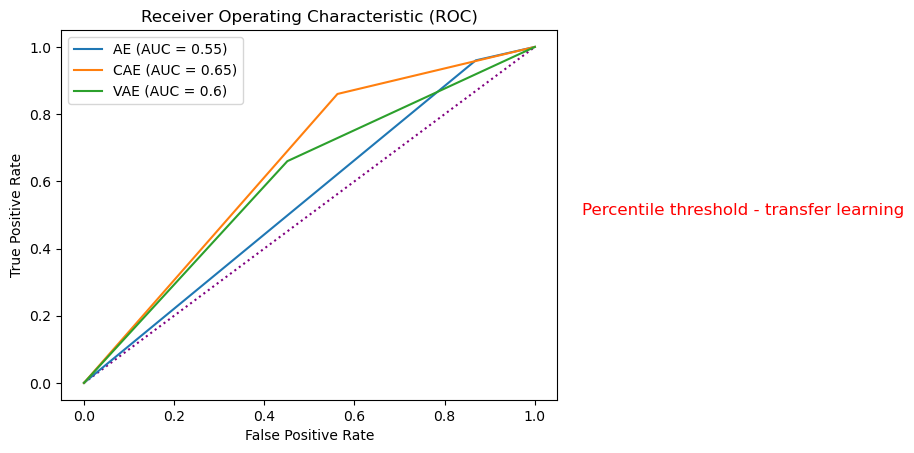

In [70]:
roc_curve_models(averages_ae, averages_cae, averages_vae, "Percentile threshold - transfer learning")

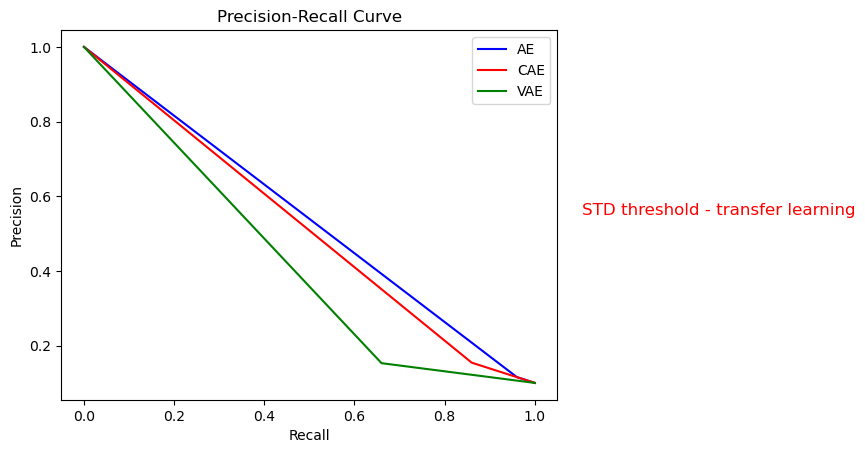

In [71]:
pr_models(averages_ae, averages_cae, averages_vae, "STD threshold - transfer learning")

Run mean_and_confidence with 200 epochs for cae, vae and then check if the averages haev significant difference to teh ones found with the transfer learning method. 

In [72]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):
    averages_cae_no_transfer, intervals_cae_no_transfer, sigmas_cae_no_trasnfer = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95, epochs=200)
    averages_vae_no_transfer, intervals_vae_no_transfer, sigmas_vae_no_trasnfer = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95, epochs=200)

# TO USE Z-TEST THE DATA HAS TO BE NORMALLY DISTRIBUTED AND POPULATION > 30

Finally take the difference between teh different average values using the z-score formula. The null hypothesis here is that there is no difference between the two means. The alternative hypothesis will instead be that mean_1 > mean_2

In [73]:
from scipy.stats import norm

#averages_cae = pd.DataFrame.from_dict(averages_cae, orient='index')
"""averages_cae_no_transfer = pd.DataFrame.from_dict(averages_cae_no_transfer, orient='index', columns=['Average'])
averages_vae = pd.DataFrame.from_dict(averages_vae, orient='index', columns=['Average'])
averages_vae_no_transfer = pd.DataFrame.from_dict(averages_vae_no_transfer, orient='index', columns=['Average'])

"""


critical = 1.645
averages_cae = dict(list(averages_cae.items())[-6:])
keys = list(averages_cae.keys())
means = pd.DataFrame(averages_cae.values(), columns=["Avg transfer"])
std = pd.DataFrame(sigmas_cae.values(), columns=["Sigma transfer"])

averages_cae_no_transfer = dict(list(averages_cae_no_transfer.items())[-6:])
means_no = pd.DataFrame(averages_cae_no_transfer.values(), columns=["Avg no transfer"])
std_no = pd.DataFrame(sigmas_cae_no_trasnfer.values(), columns=["Sigma no transfer"])

#n is equal to the iterations of the mean_confidence method
n = 5
numer = means['Avg transfer'] - means_no['Avg no transfer']
denom = np.sqrt((std['Sigma transfer']**2 / n) + (std_no['Sigma no transfer']**2 / n))
z_score = numer / denom
p_value = 2 * (1 - norm.cdf(np.abs(z_score)))

df = pd.DataFrame({'z-score': z_score, 'p-value': p_value})
df['Decision'] = ['Reject Null' if z > critical else "Don't reject null" for z in df['z-score']]
df.index = ["Accuracy", "Recall", "Precision", "F1", "Training time", "AUC"]
df.name = "CAE values"
df.head()

,z-score,p-value,Decision
Accuracy,0.649838,0.515797,Don't reject null
Recall,0.798935,0.424328,Don't reject null
Precision,0.282231,0.777767,Don't reject null
F1,1.758144,0.078723,Reject Null
Training time,-34.082750,0.000000,Don't reject null


In [74]:
critical = 1.645
averages_vae = dict(list(averages_vae.items())[-6:])
keys = list(averages_vae.keys())
means = pd.DataFrame(averages_vae.values(), columns=["Avg transfer"])
std = pd.DataFrame(sigmas_vae.values(), columns=["Sigma transfer"])

averages_vae_no_transfer = dict(list(averages_vae_no_transfer.items())[-6:])
means_no = pd.DataFrame(averages_vae_no_transfer.values(), columns=["Avg no transfer"])
std_no = pd.DataFrame(sigmas_vae_no_trasnfer.values(), columns=["Sigma no transfer"])

#n is equal to the iterations of the mean_confidence method
n = 5
numer = means['Avg transfer'] - means_no['Avg no transfer']
denom = np.sqrt((std['Sigma transfer']**2 / n) + (std_no['Sigma no transfer']**2 / n))
z_score = numer / denom
p_value = 2 * (1 - norm.cdf(np.abs(z_score)))

df = pd.DataFrame({'z-score': z_score, 'p-value': p_value})
df['Decision'] = ['Reject Null' if z > critical else "Don't reject null" for z in df['z-score']]
df.index = ["Accuracy", "Recall", "Precision", "F1", "Training time", "AUC"]
df.name = "VAE values"
df.head()

,z-score,p-value,Decision
Accuracy,-0.621294,5.344063e-01,Don't reject null
Recall,0.308607,7.576207e-01,Don't reject null
Precision,-0.290656,7.713144e-01,Don't reject null
F1,-0.086115,9.313751e-01,Don't reject null
Training time,-6.445016,1.155882e-10,Don't reject null
